# EINDOPDRACHT - CNN



## Configuration

In [61]:
from dataclasses import dataclass
from pathlib import Path

import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO


# Set seed for reproducibility:
SEED = 24
np.random.seed(SEED)
torch.manual_seed(SEED)

# Class names and their corresponding bounding box colors:
CLASS_NAMES = [
    'hex_nut',
    'washer',
    'allen_screw',
    'hex_bolt',
    'carriage_bolt',
    'barrel_nut',
    'pneumatic_fitting',
]
PALETTE_BGR = [
    (0, 0, 255),
    (0, 255, 0),
    (255, 0, 0),
    (0, 255, 255),
    (255, 0, 255),
    (255, 255, 0),
    (0, 165, 255),
]

# Training parameters:
MODEL_NAME = "yolo26m-obb.pt"
RUN_NAME = "eindopdracht"
IMG_SIZE = 1024
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
EPOCHS = 100
PATIENCE = 10
BATCH_SIZE = 4
# For reproducibility. Set to false if this raises errors during training:
DETERMINISTIC = True
# Overwrite existing RUN_NAME directory when training.
# If set to false, updates TRAIN_OUTPUT_DIR to new run folder after training:
OVERWRITE = True
RUN_TRAINING = False

# Prediction parameters:
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp"}
CONF_THRESHOLD = 0.5
NMS_IOU = 0.5
AGNOSTIC_NMS = True

# Path constants:
DATASET_DIR = Path("./cnn_dataset")
DATA_YAML = DATASET_DIR / "data.yaml"
TRAIN_OUTPUT_DIR = Path('runs') / 'obb' / RUN_NAME
OUTPUT_DIR = Path('outputs')
# Split used for prediction, orientation, CSV and images:
EVAL_SPLIT = "test"

def training_mode(run_training: bool, device: int | str) -> None:
    """
    Report training device and how to skip/run training.

    :param run_training: Whether to run training.
    :param device: Compute device: 'cpu' for CPU, or a CUDA device
        index such as 0.
    """
    if run_training:
        if device == "cpu":
            print("Will run training on CPU. Check PyTorch version if you "
                  "have a GPU to run training on.")
        else:
            print("Will run training on GPU.")
        print("Set 'RUN_TRAINING' to 'False' to not run training.")
    else:
        print("Will not run training.\n"
              "Set 'RUN_TRAINING' to 'True' to run training.")

training_mode(RUN_TRAINING, DEVICE)

Will not run training.
Set 'RUN_TRAINING' to 'True' to run training.


## Training

In [62]:
def train_model() -> Path:
    """
    Train the model and report where the best weights were saved.

    :returns: Path to the run folder (runs/obb/'RUN_NAME', or a
        numbered variant when 'OVERWRITE' is 'False').
    """
    model = YOLO(MODEL_NAME)
    model.train(
        data = str(DATA_YAML),
        epochs = EPOCHS,
        patience = PATIENCE,
        batch = BATCH_SIZE,
        imgsz = IMG_SIZE,
        device = DEVICE,
        seed = SEED,
        deterministic = DETERMINISTIC,
        exist_ok = OVERWRITE,
        name = RUN_NAME,
    )
    # With OVERWRITE = False, retraining may have created e.g. 'eindopdracht-2'
    run_dir = Path(model.trainer.save_dir)
    print(f"\nBest weights: {run_dir / 'weights' / 'best.pt'}")
    return run_dir

if RUN_TRAINING:
    TRAIN_OUTPUT_DIR = train_model()

## Training Results

Run folder: runs\obb\eindopdracht
Epochs trained: 35
Best epoch: 25
  mAP50:    0.9767
  mAP50-95: 0.8409


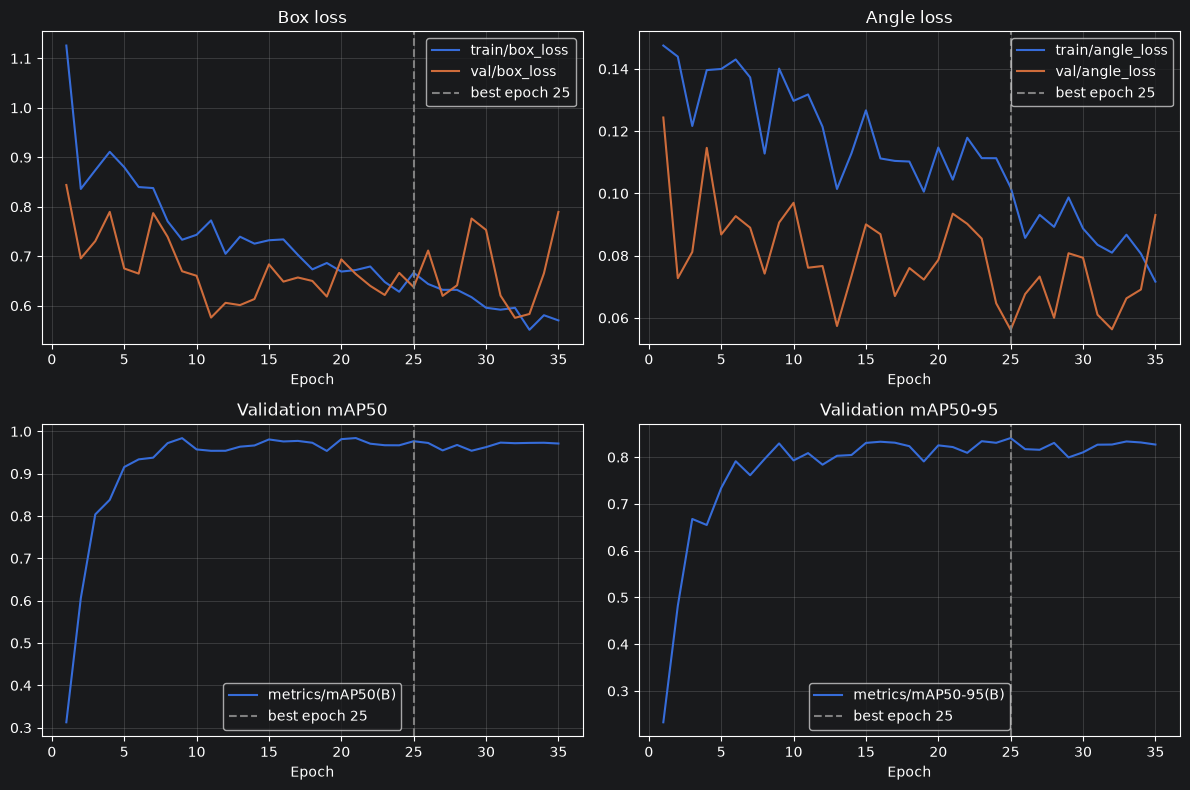

In [63]:
def load_results(train_output_dir: Path) -> pd.DataFrame:
    """
    Load per-epoch results table written by Ultralytics.

    :param train_output_dir: Path to the folder where the training
        output was written, must contain results.csv.
    :returns: Per-epoch results with whitespace stripped from column
        names.
    """
    results_path = train_output_dir / "results.csv"
    if not results_path.exists():
        raise FileNotFoundError(f"Missing results file: {results_path}")
    results = pd.read_csv(results_path)
    results.columns = results.columns.str.strip()
    return results

def best_epoch_summary(results: pd.DataFrame) -> pd.Series:
    """
    Return the row of the epoch with the highest validation mAP50-95.

    :param results: Table of results extracted from csv.
    :returns: The best epoch's row, indexed by column name.
    """
    return results.loc[results["metrics/mAP50-95(B)"].idxmax()]

def plot_training_curves(results: pd.DataFrame, best_epoch: int, output_path: Path) -> None:
    """
    Plot and display training curves and save the figure to disk.

    :param results: Table of results extracted from csv.
    :param best_epoch: Epoch number to mark with a vertical line.
    :param output_path: File path for the saved PNG. Parent folders
        are created if missing.
    """
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    epochs = results["epoch"]
    panels = [
        (axes[0, 0], ["train/box_loss", "val/box_loss"], "Box loss"),
        (axes[0, 1], ["train/angle_loss", "val/angle_loss"], "Angle loss"),
        (axes[1, 0], ["metrics/mAP50(B)"], "Validation mAP50"),
        (axes[1, 1], ["metrics/mAP50-95(B)"], "Validation mAP50-95"),
    ]
    for ax, columns, title in panels:
        for column in columns:
            ax.plot(epochs, results[column], label=column)
        ax.axvline(
            best_epoch,
            color="grey",
            linestyle="--",
            label=f"best epoch {best_epoch}",
        )
        ax.set_title(title)
        ax.set_xlabel("Epoch")
        ax.legend()
        ax.grid(alpha=0.3)
    plt.tight_layout()
    output_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_path, dpi=150)
    plt.show()

results = load_results(TRAIN_OUTPUT_DIR)
best_row = best_epoch_summary(results)
best_epoch = int(best_row["epoch"])

print(f"Run folder: {TRAIN_OUTPUT_DIR}")
print(f"Epochs trained: {len(results)}")
print(f"Best epoch: {best_epoch}")
print(f"  mAP50:    {best_row['metrics/mAP50(B)']:.4f}")
print(f"  mAP50-95: {best_row['metrics/mAP50-95(B)']:.4f}")

plot_training_curves(results, best_epoch, OUTPUT_DIR / "training_curves.png")

## Test Evaluation

In [64]:
def load_model() -> YOLO:
    """
    Load model with the best weights from disk at the global
    'TRAIN_OUTPUT_DIR'.

    :returns: The loaded YOLO model.
    """
    best_weights = TRAIN_OUTPUT_DIR / "weights" / "best.pt"
    if not best_weights.exists():
        raise FileNotFoundError(f"Missing weights: {best_weights}")

    model = YOLO(best_weights)
    print(f"Loaded: {best_weights.resolve()}")
    return model

model = load_model()

Loaded: C:\Users\sjoer\PycharmProjects\computer-vision\cnn\runs\obb\eindopdracht\weights\best.pt


In [65]:
from ultralytics.utils.metrics import OBBMetrics


def evaluate_on_test(model: YOLO) -> OBBMetrics:
    """
    Evaluate the loaded model on the test set.

    :param model: The loaded YOLO model.
    :returns: Ultralytics validation metrics for the test split.
    """
    return model.val(
        data=str(DATA_YAML),
        split="test",
        imgsz=IMG_SIZE,
        batch=BATCH_SIZE,
        device=DEVICE,
        plots=False,
    )

def print_overall_metrics(metrics: OBBMetrics) -> None:
    """
    Print the overall metrics of the test set evaluation.

    :param metrics: Ultralytics validation metrics for the test split.
    """
    box = metrics.box
    print(f"Overall  precision: {box.mp:.4f}  recall: {box.mr:.4f}")
    print(f"Overall  mAP50: {box.map50:.4f}  mAP50-95: {box.map:.4f}")

def per_class_metrics(metrics: OBBMetrics) -> pd.DataFrame:
    """
    Build a table of the per-class metrics for the test split. Rows
    follow 'box.ap_class_index', so classes missing from the split are
    omitted.

    :param metrics: Ultralytics validation metrics for the test split.
    :returns: A table of the per-class metrics.
    """
    box = metrics.box
    return pd.DataFrame({
        "class": [CLASS_NAMES[i] for i in box.ap_class_index],
        "precision": box.p,
        "recall": box.r,
        "mAP50": box.ap50,
        "mAP50-95": box.ap,
    }).round(4)

test_metrics = evaluate_on_test(model)
print_overall_metrics(test_metrics)
per_class_metrics(test_metrics)

Ultralytics 8.4.212  Python-3.14.7 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 3070, 8192MiB)
YOLO26m-obb summary (fused): 139 layers, 21,203,300 parameters, 0 gradients, 71.8 GFLOPs
val: Fast image access  (ping: 0.1±0.1 ms, read: 2740.3±380.6 MB/s, size: 5345.0 KB)
val: Scanning C:\Users\sjoer\PycharmProjects\computer-vision\cnn\cnn_dataset\labels\test.cache... 12 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 12/12 5.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.1s/it 3.3s0.4s5s
                   all         12        198      0.959      0.983      0.988      0.848
               hex_nut          8         28      0.966          1      0.995      0.865
                washer          8         50      0.974          1      0.995      0.912
           allen_screw          8         27      0.979          1      0.995      0.865
              hex_bolt          7         34      0.918      0.984    

,class,precision,recall,mAP50,mAP50-95
0,hex_nut,0.9663,1.0000,0.9950,0.8650
1,washer,0.9740,1.0000,0.9950,0.9116
2,allen_screw,0.9792,1.0000,0.9950,0.8654
3,hex_bolt,0.9177,0.9837,0.9916,0.8364
4,carriage_bolt,0.9479,1.0000,0.9950,0.8161
5,barrel_nut,0.9279,0.9286,0.9766,0.8545
6,pneumatic_fitting,0.9999,0.9677,0.9650,0.7889


## Prediction

In [66]:
@dataclass
class Detection:
    """
    Data class to hold one detected part in one image.

    :param image_filename: Name of the source image file.
    :param detection_id: Index of the detection within its image.
    :param class_id: Index into CLASS_NAMES.
    :param corners: Array of shape (4, 2) with pixel coordinates in
        corner order.
    :param confidence: Model confidence in [0, 1].
    :param orientation_deg: Longest-side angle in degrees, set by the
        orientation step.
    """
    image_filename: str
    detection_id: int
    class_id: int
    corners: np.ndarray
    confidence: float
    orientation_deg: float | None = None

    @property
    def class_name(self) -> str:
        """
        Return the human-readable name of the detected class.

        :returns: The class name from CLASS_NAMES.
        """
        return CLASS_NAMES[self.class_id]

def predict_image(model: YOLO, image_path: Path) -> list[Detection]:
    """
    Run the model on one image and wrap each detection in a Detection.

    :param model: The loaded YOLO model.
    :param image_path: Path to the image.
    :returns: One Detection per object, with orientation_deg unset.
    """
    result = model.predict(
        str(image_path),
        imgsz=IMG_SIZE,
        conf=CONF_THRESHOLD,
        iou=NMS_IOU,
        agnostic_nms=AGNOSTIC_NMS,
        device=DEVICE,
        verbose=False,
    )[0]
    obb = result.obb
    if obb is None or len(obb) == 0:
        return []
    corners_all = obb.xyxyxyxy.cpu().numpy()
    confidences = obb.conf.cpu().numpy()
    class_ids = obb.cls.cpu().numpy().astype(int)
    return [
        Detection(
            image_filename=image_path.name,
            detection_id=i,
            class_id=int(class_id),
            corners=corners_all[i],
            confidence=float(confidence),
        )
        for i, (class_id, confidence)
        in enumerate(zip(class_ids, confidences))
    ]

def predict_split(model: YOLO, split: str) -> list[Detection]:
    """
    Run the model on every image of a dataset split.

    :param model: The loaded YOLO model.
    :param split: Dataset split folder name, for example 'test'.
    :returns: All detections of the split, in image order.
    """
    image_dir = DATASET_DIR / "images" / split
    image_paths = sorted(
        p for p in image_dir.iterdir() if p.suffix.lower() in IMAGE_SUFFIXES
    )
    return [det for path in image_paths for det in predict_image(model, path)]

split = EVAL_SPLIT
detections = predict_split(model, split)
print(f"{len(detections)} detections on the {split} split")

199 detections on the test split


## Orientation

In [67]:
import math


def longest_side_angle(corners: np.ndarray) -> float:
    """
    Return the direction of the longest side of an oriented box.

    :param corners: Array of shape (4, 2) with pixel coordinates in
        corner order.
    :returns: Angle in degrees in [-90, 90), clockwise on screen.
    """
    pts = np.asarray(corners, dtype=float).reshape(4, 2)
    edge_a, edge_b = pts[1] - pts[0], pts[2] - pts[1]
    if np.linalg.norm(edge_a) >= np.linalg.norm(edge_b):
        edge = edge_a
    else:
        edge = edge_b
    angle = math.degrees(math.atan2(edge[1], edge[0]))
    return ((angle + 90.0) % 180.0) - 90.0

def longest_side_length(corners: np.ndarray) -> float:
    """
    Return the length of the longest side of an oriented box.

    :param corners: Array of shape (4, 2) with pixel coordinates in
        corner order.
    :returns: Length of the longest side in pixels.
    """
    pts = np.asarray(corners, dtype=float).reshape(4, 2)
    return float(max(
        np.linalg.norm(pts[1] - pts[0]),
        np.linalg.norm(pts[2] - pts[1]),
    ))

def angle_error(pred_deg: float, true_deg: float) -> float:
    """
    Return the absolute difference between two box angles, modulo 180
    degrees.

    :param pred_deg: Predicted angle in degrees.
    :param true_deg: Ground-truth angle in degrees.
    :returns: Error in degrees, in [0, 90].
    """
    diff = abs(pred_deg - true_deg) % 180.0
    return min(diff, 180.0 - diff)

def load_ground_truth(
        split: str,
        image_filename: str,
        width: int,
        height: int,
) -> list[dict]:
    """
    Read the YOLO-OBB label file of one image and convert it to pixel
    coordinates.

    :param split: Dataset split folder name, for example 'test'.
    :param image_filename: Name of the image file the labels belong to.
    :param width: Image width in pixels.
    :param height: Image height in pixels.
    :returns: One dict per labeled object with 'class_id', 'corners'
        and 'angle_deg'.
    """
    label_path = (DATASET_DIR / "labels" / split /
                  f"{Path(image_filename).stem}.txt")
    objects = []
    if not label_path.exists():
        return objects
    for line in label_path.read_text().splitlines():
        if not line.strip():
            continue
        values = line.split()
        corners = np.array(values[1:9], dtype=float).reshape(4, 2)
        corners[:, 0] *= width
        corners[:, 1] *= height
        objects.append({
            "class_id": int(values[0]),
            "corners": corners,
            "angle_deg": longest_side_angle(corners),
        })
    return objects

def set_orientations(detections: list[Detection]) -> None:
    """
    Set orientation_deg on every detection from its corners, in place.

    :param detections: Detections from predict_split.
    """
    for det in detections:
        det.orientation_deg = longest_side_angle(det.corners)

def orientation_errors(
        detections: list[Detection],
        split: str,
) -> pd.DataFrame:
    """
    Pair each labeled object with the nearest same-class detection and
    measure the angle error.

    A pair is only accepted if the centers lie within half the labeled
    object's longest side.
    Labeled objects without an accepted pair are kept in the table
    with no error, and the number of unpaired objects is printed.

    :param detections: Detections with orientation_deg set, from
        set_orientations.
    :param split: Dataset split folder name, for example 'test'.
    :returns: One row per labeled object with class_name, paired and
        angle_error_deg.
    """
    image_dir = DATASET_DIR / "images" / split
    images = sorted(
        p.name for p in image_dir.iterdir()
        if p.suffix.lower() in IMAGE_SUFFIXES
    )
    rows = []
    for filename in images:
        image = cv2.imread(str(DATASET_DIR / "images" / split / filename))
        if image is None:
            raise FileNotFoundError(f"Could not read image: {filename}")
        height, width = image.shape[:2]
        image_dets = [d for d in detections if d.image_filename == filename]
        for truth in load_ground_truth(split, filename, width, height):
            centre = truth["corners"].mean(axis=0)
            row = {
                "image_filename": filename,
                "class_name": CLASS_NAMES[truth["class_id"]],
                "paired": False,
                "angle_error_deg": np.nan,
            }
            candidates = [
                d for d in image_dets if d.class_id == truth["class_id"]
            ]
            if candidates:
                nearest = min(
                    candidates,
                    key=lambda d: np.linalg.norm(
                        d.corners.mean(axis=0) - centre
                    ),
                )
                distance = np.linalg.norm(
                    nearest.corners.mean(axis=0) - centre
                )
                if distance <= 0.5 * longest_side_length(truth["corners"]):
                    row["paired"] = True
                    row["angle_error_deg"] = angle_error(
                        nearest.orientation_deg,
                        truth["angle_deg"],
                    )
            rows.append(row)
    errors = pd.DataFrame(rows)
    print(
        f"Unpaired labelled objects: "
        f"{(~errors['paired']).sum()} of {len(errors)}"
    )
    return errors

def summarize_orientation(errors: pd.DataFrame) -> pd.DataFrame:
    """
    Summarize angle errors of paired objects per class and overall.

    :param errors: Output of orientation_errors.
    :returns: Count, median, mean, and share within 5 and 10 degrees,
        per class and for 'all'.
    """
    paired = errors[errors["paired"]].copy()
    paired["within_5"] = paired["angle_error_deg"] <= 5
    paired["within_10"] = paired["angle_error_deg"] <= 10
    summary = paired.groupby("class_name").agg(
        count=("angle_error_deg", "size"),
        median=("angle_error_deg", "median"),
        mean=("angle_error_deg", "mean"),
        within_5=("within_5", "mean"),
        within_10=("within_10", "mean"),
    )
    summary.loc["all"] = [
        len(paired),
        paired["angle_error_deg"].median(),
        paired["angle_error_deg"].mean(),
        paired["within_5"].mean(),
        paired["within_10"].mean(),
    ]
    return summary.round(2)

set_orientations(detections)
orientation_table = orientation_errors(detections, EVAL_SPLIT)
summarize_orientation(orientation_table)

Unpaired labelled objects: 5 of 198


,count,median,mean,within_5,within_10
class_name,,,,,
allen_screw,27,1.70,1.75,0.96,1.00
barrel_nut,13,3.48,7.51,0.54,0.69
carriage_bolt,14,0.85,1.14,1.00,1.00
hex_bolt,33,1.47,2.05,0.91,1.00
hex_nut,28,40.62,38.84,0.11,0.25
pneumatic_fitting,28,2.65,4.91,0.82,0.93
washer,50,4.79,25.58,0.50,0.64
all,193,2.48,14.16,0.66,0.77


## CSV Export

In [68]:
CSV_COLUMNS = [
    "image_filename", "detection_id", "class_id", "class_name",
    "x1", "y1", "x2", "y2", "x3", "y3", "x4", "y4",
    "orientation_deg", "confidence",
]

def detections_to_rows(detections: list[Detection]) -> pd.DataFrame:
    """
    Flatten detections into one row per detection, with corners split
    into x and y columns.

    :param detections: Detections with orientation_deg set, from
        set_orientations.
    :returns: Table with the columns in CSV_COLUMNS.
    """
    rows = []
    for det in detections:
        row = {
            "image_filename": det.image_filename,
            "detection_id": det.detection_id,
            "class_id": det.class_id,
            "class_name": det.class_name,
            "orientation_deg": round(det.orientation_deg, 2),
            "confidence": round(det.confidence, 4),
        }
        for corner in range(4):
            row[f"x{corner + 1}"] = round(float(det.corners[corner, 0]), 1)
            row[f"y{corner + 1}"] = round(float(det.corners[corner, 1]), 1)
        rows.append(row)
    return pd.DataFrame(rows, columns=CSV_COLUMNS)


def export_detections_csv(
    detections: list[Detection],
    output_path: Path,
) -> pd.DataFrame:
    """
    Write the detections to a CSV file.

    :param detections: Detections with orientation_deg set, from
        set_orientations.
    :param output_path: File path for the CSV. Parent folders are created if
        missing.
    :returns: The exported table.
    """
    if any(det.orientation_deg is None for det in detections):
        raise ValueError(
            "Run the orientation cell before exporting, so every detection "
            "has an angle."
        )
    table = detections_to_rows(detections)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    table.to_csv(output_path, index=False)
    return table


detections_table = export_detections_csv(
    detections,
    OUTPUT_DIR / "detections_test.csv",
)
print(f"Wrote {len(detections_table)} rows to "
      f"{(OUTPUT_DIR / 'detections_test.csv').resolve()}")
detections_table.head()

Wrote 199 rows to C:\Users\sjoer\PycharmProjects\computer-vision\cnn\outputs\detections_test.csv


,image_filename,detection_id,class_id,class_name,x1,y1,x2,y2,x3,y3,x4,y4,orientation_deg,confidence
0,20261106_132042.jpg,0,0,hex_nut,1228.8,1955.7,1216.8,1823.5,1074.4,1836.4,1086.3,1968.6,-5.17,0.8941
1,20261106_132205.jpg,0,3,hex_bolt,1319.7,1792.7,1319.9,1623.1,807.0,1622.7,806.8,1792.2,0.05,0.9567
2,20261106_132205.jpg,1,5,barrel_nut,1931.6,1510.6,1935.6,1287.8,1793.8,1285.3,1789.8,1508.1,-88.98,0.9523
3,20261106_132205.jpg,2,3,hex_bolt,1899.4,1846.7,1905.7,1676.5,1384.6,1657.3,1378.3,1827.5,2.11,0.9515
4,20261106_132205.jpg,3,1,washer,1250.4,2141.4,1246.9,1922.2,1019.3,1925.9,1022.8,2145.1,-0.91,0.9490


## Visualization

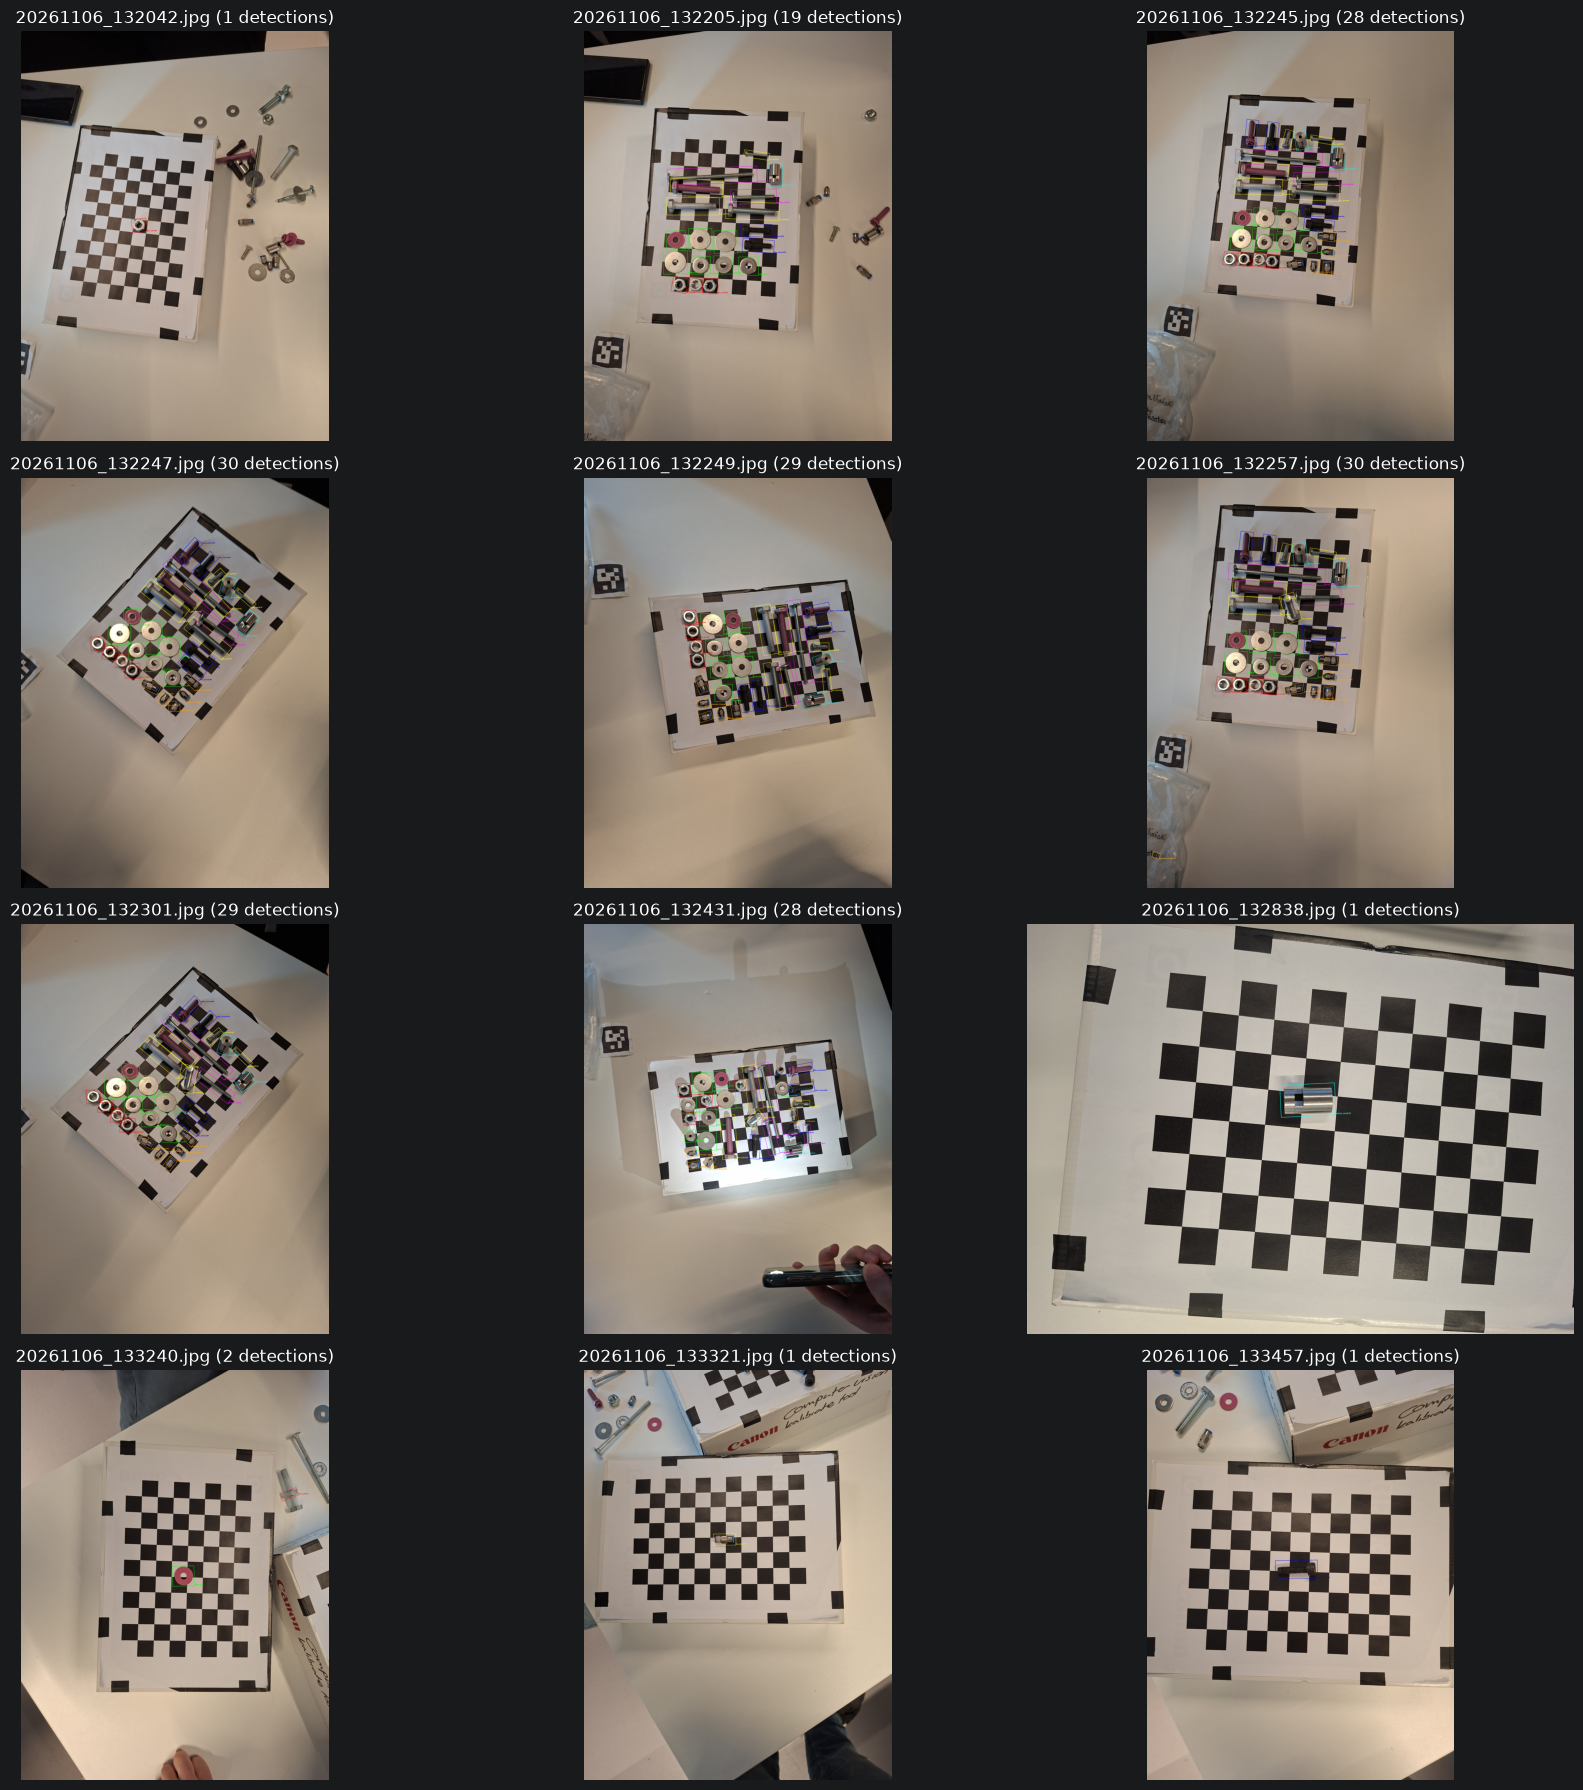

Saved 12 images to C:\Users\sjoer\PycharmProjects\computer-vision\cnn\outputs\predictions


In [69]:
def draw_detections(
    detections: list[Detection],
    split: str,
) -> tuple[dict[str, np.ndarray], dict[str, int]]:
    """
    Draw the oriented boxes of every image of a split once.

    :param detections: Detections from predict_split.
    :param split: Dataset split folder name, for example 'test'.
    :returns: A tuple of the drawn BGR image per filename and the
        number of detections per filename. Only images with at least
        one detection are included.
    """
    by_image: dict[str, list[Detection]] = {}
    for det in detections:
        by_image.setdefault(det.image_filename, []).append(det)

    drawn: dict[str, np.ndarray] = {}
    counts: dict[str, int] = {}
    for filename, image_dets in sorted(by_image.items()):
        image = cv2.imread(str(DATASET_DIR / "images" / split / filename))
        if image is None:
            raise FileNotFoundError(f"Could not read image: {filename}")
        for det in image_dets:
            colour = PALETTE_BGR[det.class_id]
            pts = det.corners.astype(np.int32).reshape(-1, 1, 2)
            cv2.polylines(
                image,
                [pts],
                isClosed=True,
                color=colour,
                thickness=2,
            )
            label = f"{det.class_name} {det.confidence:.2f}"
            x, y = pts[0, 0]
            cv2.putText(
                image,
                label,
                (int(x),
                max(15, int(y) - 5)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                colour,
                2,
            )
        drawn[filename] = image
        counts[filename] = len(image_dets)
    return drawn, counts

def show_drawn(
    drawn: dict[str, np.ndarray],
    counts: dict[str, int],
    max_images: int = 12,
) -> None:
    """
    Show drawn images in a grid.

    :param drawn: Drawn BGR image per filename, from draw_detections.
    :param counts: Number of detections per filename, used in the
        titles.
    :param max_images: Maximum number of images to show.
    """
    filenames = list(drawn)[:max_images]
    cols = 3
    rows = math.ceil(len(filenames) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 4.5 * rows))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, filename in zip(np.ravel(axes), filenames):
        ax.imshow(cv2.cvtColor(drawn[filename], cv2.COLOR_BGR2RGB))
        ax.set_title(f"{filename} ({counts[filename]} detections)")
    plt.tight_layout()
    plt.show()

def export_drawn(drawn: dict[str, np.ndarray], output_dir: Path) -> None:
    """
    Write each drawn image to output_dir as a JPEG and report the
    location.

    :param drawn: Drawn BGR image per filename, from draw_detections.
    :param output_dir: Folder to write the images to. Created if
        missing.
    """
    output_dir.mkdir(parents=True, exist_ok=True)
    for filename, image in drawn.items():
        cv2.imwrite(
            str(output_dir / f"{Path(filename).stem}_pred.jpg"),
            image,
        )
    print(f"Saved {len(drawn)} images to {output_dir.resolve()}")


drawn_images, counts = draw_detections(detections, EVAL_SPLIT)
show_drawn(drawn_images, counts)
export_drawn(drawn_images, OUTPUT_DIR / "predictions")